### Выполнили: Богославская Анна, Павлеева Мария, Староверова Анна

In [1]:
## импортируем нужные библиотеки

import pandas as pd
import numpy as np
import seaborn as sns
import scipy as sc
import math
from scipy.stats import norm
import plotly.express as px
import matplotlib.pyplot as plt
from datetime import date, timedelta
from itertools import chain


import warnings
warnings.filterwarnings('ignore')

In [2]:
## !pip install openpyxl

## Задание №1

### Модель Кокса-Ингерсолла-Росса (CIR) для процентных ставок:
Стохастическое дифференциальное уравнение (SDE):

$dr_t = \alpha(\theta - r_t)dt + \sigma\sqrt{r_t}dW_t$

где: 
- $r_t$ -  процентная ставка в момент времени t 
- $\alpha$ - коэффициент возврата к среднему
- $\theta$ - уровень средней процентной ставки
- $\sigma$ - волатильность
- $dW_t$ - инкремент винеровского процесса

### Обоснование/стратегия выбора параметров:
- Волатильность (σ): волатильность возможно вычислить для симуляций следующим образом: $sigma$ = std($rt$)/np.sqrt(n_days), таким образом, мы сможем численно выразить волатильность для наблюдаемых ставок на каждый день в историческом периоде 

Для выбора параметров $\alpha$ и $\theta$: 
- Коэффициент возврата к среднему (a) и Уровень средней процентной ставки (θ) можно найти полуавтоматическим способом: путем подбора значений гиперпараметров при минимизации ф-ии ошибок (классический МНК) при симуляции данных. Код для такого решения мы предоставили чуть ниже, предалагаемый варинат подсмотрели [тут](https://quant.stackexchange.com/questions/75943/cir-model-calibration-python)



### Модель для обменного курса:
Данная модель описывает изменение обменного курса: находит Fx-rate через разницу отношений rF (foreign) и rd (domestic) значений мнговенных ставок :

$dX_t = \mu dt + \sigma dW_t$, где $\mu = (rF-rD)$

где: 
- $X_t$ -  логарифм обменного курса в момент времени t 
- $\mu$ - скорость возврата к среднему
- $\sigma$ - волатильность
- $dW_t$ - инкремент винеровского процесса
-  rF - foreign rate
-  rD - domestic rate 

Источник данных [MosPrime](https://mosprime.com/archive?date_from=2020-12-10&date_to=2022-12-12&contributor=)

Источник данных [SOFR](https://www.newyorkfed.org/markets/reference-rates/sofr)

Источник данных для обменного курса [USD_RUB](https://www.investing.com/currencies/usd-rub-historical-data)

In [7]:
#Выгружаем данные скачанные из архивов MosPrime и SOFR
def read_and_merge_data(file_path):
    rub_inter = pd.read_excel(file_path, sheet_name='MosPrime')
    usd_inter = pd.read_excel(file_path, sheet_name='SOFR')
    USD_RUB = pd.read_excel(file_path, sheet_name='USD_RUB')

    rub_inter.columns = ['date', 'MosPrime']
    usd_inter.columns = ['date', 'SOFR']

    for df in [rub_inter, usd_inter, USD_RUB] :
        df['date'] = pd.to_datetime(df['date'])
    df_core = rub_inter.merge(usd_inter, on='date').merge(USD_RUB, on='date')
    
    return df_core

file_path = './stoch_proc_data.xlsx'
df_core = read_and_merge_data(file_path)

In [8]:
df_core.head()

,date,MosPrime,SOFR,USD_RUB
0,2022-01-12,7.37,3.82,74.7154
1,2022-11-30,7.34,3.82,60.9900
2,2022-11-29,7.24,3.81,61.0225
3,2022-11-28,7.22,3.80,61.2275
4,2022-11-25,7.27,3.80,60.5025


In [37]:
def find_var_matrix(df_core, find_increments = True, find_percent = True, start_date = '2021-12-10'):
  '''
  
  df_core - наш оригинальный датафрейм с выгруженными данными по проц. ставкам и обмен. курсу
            формат: 'USD', 'RUB' and 'USD_RUB' - колонки именно в таком нейминге
  find_increments = True, параметр, указывающий хотим ли мы работать с приростами ставок или осн. зн. проц. ставок
  find_percent = True, параметр, указывающий хотил ли мы переводить процентные ставки к долям (7% --> 0.07)
  start_date - дата начала симуляции (используем здесь, чтобы считать корреляции на исторических данных)
  
  '''

  df_core['date'] = pd.to_datetime(df_core['date'])
  df_core = df_core.sort_values(by = 'date', ascending = True)
  df_core['SOFR'] = df_core['SOFR'].astype(float)
  df_core['MosPrime'] = df_core['MosPrime'].astype(float)

  #  находим  приросты, если нужно
  if find_increments:
    for col in ['MosPrime',  'SOFR']:
      df_core[col] = df_core[col] - df_core[col].shift(1).bfill()
  # находим доли, если нужно
  if find_percent:
      for col in ['MosPrime',  'SOFR']:
          df_core[col] = df_core[col] / 100

  # находим разложение Холецкого
  corr_matrix = df_core[df_core['date'].dt.date < date.fromisoformat(start_date)].loc[:, ['MosPrime',  'SOFR',  'USD_RUB']].corr()
  chol = np.linalg.cholesky(corr_matrix)

  return df_core, chol

df, chol = find_var_matrix(df_core, find_increments = False)

Здесь хочется дополнительно остановиться на некоторых моментах:

При нахождении корреляции происходит центрирование факторов, которое нивелирует детерминированную компоненту в схеме Эйлера-Муроямы для решению диффуров, поэтому дрифт не оказывает влияние на корреляцию, а ее мы используем только для стохастической части

Домножается на стохастическую часть не просто корреляционная матрица ( из которой нам по сути нужна только дисперсия), но ближайшая положительно определенная по норме матрица. Ее как раз можно найти с помощью разложения Холецкого. 

In [10]:
#хочется посмотреть на консистеность данных временных рядов
data_check_dates = df.copy() 
data_check_dates = data_check_dates.sort_values(by='date')

# посмотрим инфо интервалов по дате
data_check_dates['delta'] = data_check_dates['date'] - data_check_dates['date'].shift(1)
data_check_dates[['date', 'delta']][:100]
#много пропусков, поэтому удалим дни, когда нет метрик по месяцам (>30 дней)

,date,delta
408,2020-10-12,NaT
407,2020-11-12,31 days
406,2020-12-14,32 days
405,2020-12-15,1 days
404,2020-12-16,1 days
...,...,...
296,2021-06-07,3 days
276,2021-06-08,1 days
238,2021-06-10,2 days
308,2021-06-15,5 days


In [11]:
df = df.loc[df['date'].dt.date >= date.fromisoformat('2020-12-14')]
#далее работает именно с предобработанным датафреймом

In [12]:
chol

array([[ 1.        ,  0.        ,  0.        ],
       [ 0.25988095,  0.96564066,  0.        ],
       [-0.44660159, -0.0747211 ,  0.89160741]])

In [13]:
fig = px.line(df, x='date', y=['SOFR', 'MosPrime'],
              title='''Значения процентных ставок доллара и рубля за период 10.12.2020-9.12.2022''')
fig.show()

In [14]:
fig = px.line(df, x='date', y=['USD_RUB'],
              title='Значения обменного курса USD_RUB за 12.10.2020-8.12.2022 год')
fig.show()

### Выбор оптимальных параметров

In [15]:
from scipy.optimize import minimize

def cir_model_opt_params(params, r, dt):
    alpha, theta, sigma = params
    dw = np.random.normal(0, np.sqrt(dt))
    dr = alpha * (theta - r) * dt + sigma * np.sqrt(r) * dw
    return dr

def objective_function(params, r):
    dt = 1/12  
    error = 0
    for n in range(len(r)):
        error_ = r[n] - cir_model_opt_params(params, r[n], dt)
        error += error_**2
    return error


#Калибровка параметров для ставки рубля
interest_rates_rub = df['MosPrime']
initial_params_rub = [0.01, df['MosPrime'].mean(), (df['MosPrime'].std())/np.sqrt(len(df))]
result_rub = minimize(objective_function, initial_params_rub, args=(interest_rates_rub,),
                      method='Nelder-Mead')
calibrated_params_rub = result_rub.x

#Калибровка параметров для ставки доллара
interest_rates_usd = df['SOFR']
initial_params_usd = [0.01, df['SOFR'].mean(), (df['SOFR'].std())/np.sqrt(len(df))]
result_usd = minimize(objective_function, initial_params_usd, args=(interest_rates_usd,), 
                      method='Nelder-Mead')
calibrated_params_usd = result_usd.x

# # #Калибровка параметров для обменного курса рубль/доллап
interest_rates_exch = df['USD_RUB']
initial_params_exch = [0.1, df['USD_RUB'].mean(), (df['USD_RUB'].std())/np.sqrt(len(df))]
result_exch = minimize(objective_function, initial_params_exch, args=(interest_rates_exch,),
                       method='Nelder-Mead')
calibrated_params_exch = result_exch.x

# np.set_printoptions(suppress=True)

print("Calibrated Parameters for MosPrime:", calibrated_params_rub)
print("Calibrated Parameters for SOFR:", calibrated_params_usd)
print("Calibrated Parameters for USD_RUB:", calibrated_params_exch)

Calibrated Parameters for MosPrime: [0.01034777 0.08354349 0.0020544 ]
Calibrated Parameters for SOFR: [0.01012037 0.00749051 0.00058203]
Calibrated Parameters for USD_RUB: [ 0.10105667 75.27637036  0.50599769]


In [16]:
kappa_usd, theta_usd, sigma_usd = 0.001030556, 0.00727783, 0.056626
kappa_rub, theta_rub, sigma_rub = 0.00951332, 0.08531317, 0.0209946
kappa_exch, theta_exch, sigma_exch = 0.09969558, 73.91324226, 0.52598502

In [17]:
#Техническая ячейка для проверки скетча кода для CIR модели, можно не запускать
# def cir_model_test(initial_rate, kappa, theta, sigma, T, dt, sim):
    
#     num_periods = int(T / dt)
#     rate_list = []
#     cholesky_matrix = np.linalg.cholesky(df.corr())
    
#     for j in range(sim):
#         rates = np.zeros(num_periods)
#         rates[0] = initial_rate

#         for i in range(1, num_periods):
#             dW = np.random.normal(0, np.sqrt(dt), size = 3)
#             dW = cholesky_matrix @ dW
#             rates[i] = rates[i-1] + kappa * (theta - rates[i - 1]) + sigma * np.sqrt(rates[i - 1]) * dW[1]
#         rate_list.append(rates)
#     return rate_list

In [18]:
#Техническая ячейка для проверки скетча основной ф-ии для CIR, прогонять не надо
#usd_list = cir_model_test(df.SOFR.mean(), kappa_usd, theta_usd, sigma_usd, T=1.0, dt= 1/365, sim= 20)

In [19]:
def plot():
    plt.figure(figsize = (20,6))
    plt.subplot(131)

    for i in usd_list:
        plt.plot(i)
    plt.title('Долларовая ставка')
    plt.plot(np.mean(np.array(usd_list), axis = 0), linewidth = 3, c= 'b', label = 'mean_sim')
    plt.legend()


    plt.subplot(132)

    for i in rub_list:
        plt.plot(i)
    plt.title('Рублевая ставка')
    plt.plot(np.mean(np.array(rub_list), axis = 0), linewidth = 3, c= 'b', label = 'mean_sim')
    plt.legend() 

    plt.subplot(133)

    for i in ech_list:
        plt.plot(i)
    plt.title('Обменный курс')
    plt.plot(np.mean(np.array(ech_list), axis = 0), linewidth = 3, c= 'b', label = 'mean_sim')
    plt.legend()

    plt.show()

### Вид уравнения для симуляции модели обменного курса:

$$ X_t = X_{t-1} + X_{t-1}(r_f - r_d) \Delta t + X_{t-1}\sigma (W_t - W_{t-1})$$


### Вид уравнения для симуляции процентных ставок:

$$ r_t = r_{t-1} + \alpha (\theta _{t-1} - \cdot r_{t-1}) \Delta t + \sigma (W_t - W_{t-1})$$

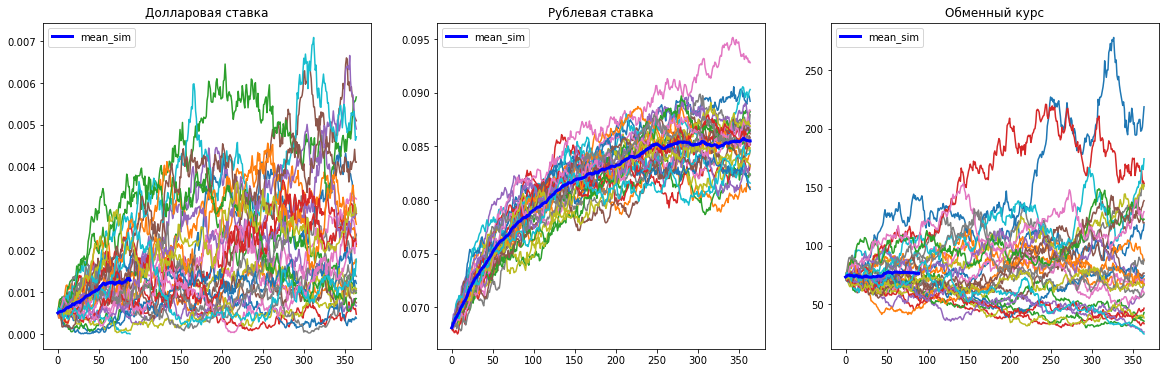

In [20]:
def cir_model(df, num_simulations, T, dt, kappa_usd, theta_usd, sigma_usd, kappa_rub, theta_rub,
              sigma_rub, kappa_exch, theta_exch, sigma_exch, start_date): 
    
    df = df.dropna()
    num_periods = int(T / dt)
    rub_list = []
    usd_list = []
    ech_list = []
    cholesky_matrix = np.linalg.cholesky(df.corr())
    
    for sim in range(num_simulations):
        rates_dollar = np.zeros(num_periods)
        rates_ruble = np.zeros(num_periods)
        exch_rates = np.zeros(num_periods)

        
        rates_dollar[0] = df[df['date'].dt.date == date.fromisoformat(start_date)].SOFR
        rates_ruble[0] = df[df['date'].dt.date == date.fromisoformat(start_date)].MosPrime
        exch_rates[0] = df[df['date'].dt.date == date.fromisoformat(start_date)].USD_RUB
        
        for i in range(1, num_periods):

            dW = np.random.normal(0, np.sqrt(dt), size = 3)
            dW_corr = cholesky_matrix @ dW
            
            rates_dollar[i] = rates_dollar[i-1]  + kappa_usd * (theta_usd - rates_dollar[i - 1]) + sigma_usd * np.sqrt(rates_dollar[i - 1]) * dW_corr[1]
            rates_ruble[i] = rates_ruble[i-1] + kappa_rub * (theta_rub - rates_ruble[i - 1]) + sigma_rub * np.sqrt(rates_ruble[i - 1]) * dW_corr[0]
            exch_rates[i] = exch_rates[i-1] + exch_rates[i-1]*(rates_ruble[i-1] - rates_dollar[i-1])* dt + exch_rates[i- 1]* sigma_exch*dW[2]
    
        rub_list.append(rates_ruble)
        usd_list.append(rates_dollar)
        ech_list.append(exch_rates)

    return rub_list, usd_list, ech_list


rub_list, usd_list, ech_list = cir_model(df, num_simulations=30, T=1.0, dt=1/365,
                    kappa_usd=kappa_usd, theta_usd=theta_usd, sigma_usd=sigma_usd,
                    kappa_rub=kappa_rub, theta_rub=theta_rub, sigma_rub=sigma_rub, 
                    kappa_exch=kappa_exch, theta_exch=theta_exch, sigma_exch=sigma_exch, start_date = '2021-12-10')

plot()

Мы провели по 30 симуляций для каждого риск-фактора и получили отображения выше (несмотря на то, что оптимальным кол-вом симуляций мы выделили n >= 85, для наглядности и быстроты работы ноута оставили 30. Пояснение см - конец ноутбука, Задание №2). 

Комментарии по графикам: 

- Видим, что долларовая ставка и рублевая ставка имеют выраженные восходящие тренды, но с разными формами. Это связано с инициализирующими параметрами для этих факторов:

- Долларовая ставка: скорость возврата к среднему, среднее, волатильность = 0.001030556, 0.00727783, 0.056626 (соответсвенно)

- Рублевая ставка: скорость возврата к среднему, среднее, волатильность = 0.00951332, 0.08531317, 0.0209946 (соответсвенно)

- В то же время обменного курса видим довольно стабильную динамику: для этого фактора основное влияние имеет стохастическая часть, поскольку разница между абсолютными значениями ключевых ставок очень мала и практически не вносит вклад в симуляции. В дальнейшем мы рассматриваем некоторые альтернативы, помогающие нам сильнее учесть изменения детерминированной части, а не только стохастической 

## Задание №2

На основании симуляций динамики обменного курса для пары рубль-долллар необходимо было оценить справедливую стоимость для продукта Range Accrual. 

Range Accrual (Рендж-Акруал) - это финансовый дериватив, представляющий собой контракт между двумя сторонами, в котором одна сторона (обычно инвестор или инвестиционный фонд) получает выплаты в зависимости от того, находится ли определенная переменная (например, обменный курс, процентная ставка) в пределах определенного диапазона (ренджа) в течение определенного периода времени.

Основные компоненты контракта Range Accrual включают:

- Верхняя и нижняя границы (Рендж): Диапазон значений переменной, в пределах которого должна находиться переменная для получения выплат.
- Номинал: Максимальная выплата, которую инвестор может получить в случае выполнения условий контракта.
- Период: Временной интервал, в течение которого проверяется условие нахождения переменной в рендже.


Таким образом, выплаты по контракту Range Accrual зависят от того, находится ли переменная (например, обменный курс) внутри или вне заданного диапазона в каждый момент времени в течение установленного периода. Этот тип дериватива часто используется для управления рисками валютных курсов или процентных ставок.

#### Обоснование: 
Логика которой мы придерживались для написания кода ф-ии второго задания: 
- Допустим, у нас есть 4 значения симуляция для дня 1-3, см таблицу ниже: 

Day1 | Day2 |  Day3 | 
-----|------|-------|
0.1, | 0.14 | 0.1   |
0.2, | 0.2. | 0.3   |
0.3, | 0.36.| 0.6   |
0.4  | 0.4. | 0.87  |

- Номинал, с котором мы вступаем в контракт = 100 руб. Таким образом, зная период (в сколько дней мы вступаем с заданным номиналом), мы можем рассчитать сколько денег мы получим в рамках сделки за 1 день, поделив весь размер номинала на кол-во дней в в периоде (в случае примера это - 100/3)
- Допустим, границы нашего интервала = [0.15, 0.35]
- Тогда для Day 1, p(успеха day 1) = вероятность того, что из с-симулированных нами значений есть значения, попавшие внуть заданного интервала. p(успеха day 1) =  1/2 (50%, [0.2, 0.3]) 
- Для Day 2 и Day 3 эта вероятность равняется 25%
- Справедливую выплату по контракту можно рассчитать таким образом: p(успеха day 1) * (100/3) + p(успеха Day 2) * (100/3) + p(успеха Day 3) * (100/3 ) = 15 руб + 7.5 руб + 7.5 руб
- Total : 30 руб 

In [27]:
def sumilate_dataset(df, num_simulations, start_date, end_date): 
    '''
    df - исходный датафрейм, из которого мы будем брать нужный период и данные
    num_simulations - колво симуляций
    start_date, end_date - даты начала и конца периода

    '''

    df_new_time_intertval = df.loc[(df['date'].dt.date >= date.fromisoformat(start_date)) & 
                (df['date'].dt.date <= date.fromisoformat(end_date))].reset_index(drop = True)
            
    date_range = df_new_time_intertval.shape[0] 

    _, _, data = cir_model(df_new_time_intertval, num_simulations= num_simulations, T=date_range/365, dt=1/365,
                    kappa_usd=kappa_usd, theta_usd=theta_usd, sigma_usd=sigma_usd,
                    kappa_rub=kappa_rub, theta_rub=theta_rub, sigma_rub=sigma_rub, 
                    kappa_exch=kappa_exch, theta_exch=theta_exch, sigma_exch=sigma_exch,
                           start_date = start_date)
    
    data = pd.DataFrame(data)
    return date_range, data 

num_days, sim_data = sumilate_dataset(df, 30, '2021-12-10', '2021-12-27')

In [28]:
def calculate_pricing(df, upper_bound = None, lower_bound = None, nominal = 100):
    '''
    df - датафрейм, полученный как выход функции sumilate_dataset, т.е. имеющий только необходимые данные для симуляции
    upper_bound - верхняя граница (или ее отсутствие). При заданной верхней границе считаем успехом непревышение ее
    lower_bound - нижняя граница (или ее отсутствие). При заданной нижней границе считаем успехом опускание не ниже ее
    nominal - номинал сделки - максимальная сумма, которую можно получить в случае успешного реализации сценария в каждый день периода
    
    '''
    
    date_range = df.shape[1]
    per_day_nominal = nominal/date_range ## 100/3
    
    # Вероятность не превысить заданные границы интервалов (когда они есть) 
    if (upper_bound is not None) and (lower_bound is not None):
        in_range_list = []
        for col in range(len(df.columns)): ## колонка - одна симуляция (столбец) с date_range строк 
            in_range = df[(df.iloc[:, col] <= upper_bound) & (df.iloc[:, col] >= lower_bound)].shape[0]
            in_range_list.append((in_range/df.shape[0]) * per_day_nominal)
        fair_rate = sum(in_range_list)
                    
            
    # Вероятность не превысить верхнюю граниницу (если задана)
    elif upper_bound is not None:
        in_range_list = [] ##  тут будет лежать date_range 
        for col in range(len(df.columns)):
            in_range = df[df.iloc[:, col] <= upper_bound].shape[0]
            in_range_list.append((in_range/df.shape[0]) * per_day_nominal)
        fair_rate = sum(in_range_list)
    
    # Вероятность не снизиться сильнее нижней границы (если задана)
    elif lower_bound is not None:
        in_range_list = [] ##  тут будет лежать date_range 
        for col in range(len(df.columns)):
            in_range = df[df.iloc[:, col] >= lower_bound].shape[0]
            in_range_list.append((in_range/df.shape[0]) * per_day_nominal)
        fair_rate = sum(in_range_list)

    else:
        fair_rate = nominal  # Если нижняя граница не задана, считаем равным номиналу за период
    
    
    return fair_rate

In [29]:
fair_rate = calculate_pricing(df = sim_data, upper_bound  = 74, lower_bound = None, nominal = 100)
print(f"Значение справедливой стоимости для инструмента Range Accural: {fair_rate}")

Значение справедливой стоимости для инструмента Range Accural: 55.151515151515156


In [31]:
## Техническая ячейка - проверяем, что все корректно работает

# data_1 = pd.DataFrame(sim_data)
# print(data_1[data_1.iloc[:, 0] < 74].shape ,data_1[data_1.iloc[:, 1] < 74].shape)
# a = 0
# for i in range(11):
#     ## print(data_1[data_1.iloc[:, i] < 74].shape[0]/data_1.shape[0] * (100/11))
#     a += data_1[data_1.iloc[:, i] < 74].shape[0]/data_1.shape[0] * (100/11)
#     print(a)

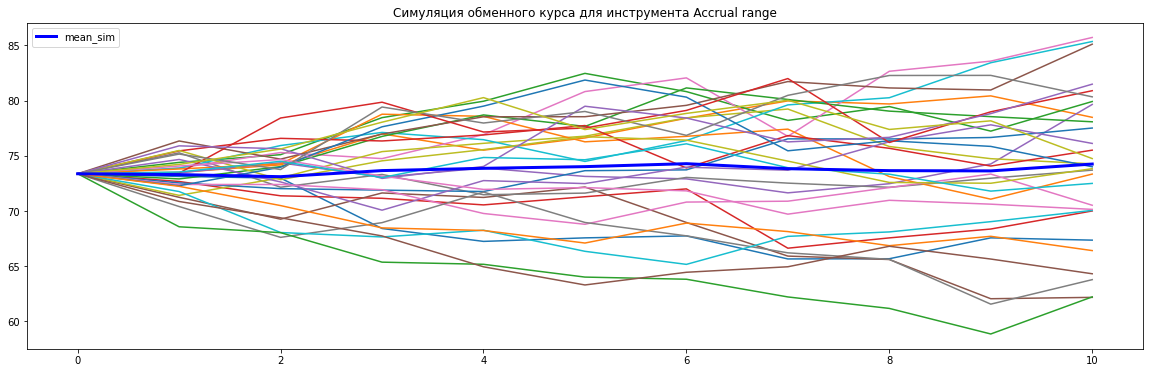

In [32]:
def plot_sec_task(sim_data):
    plt.figure(figsize = (20,6))

    for i in range(len(sim_data)): 
        plt.plot(sim_data.iloc[i, :])
    plt.title('Симуляция обменного курса для инструмента Accrual range')
    plt.plot(np.mean(np.array(sim_data), axis = 0), linewidth = 3, c= 'b', label = 'mean_sim')
    plt.legend()

    plt.show() 

plot_sec_task(sim_data)

### Альтернативная модель для обменного курса

На наш взгляд, абсолютная разница между мгновенными ставками рубля и доллара слишком малая (исходная модель не учитывает коэффициент значимости для этого параметра), а так же всегда направлена в одну сторону, что может порождать единонаправленный дрифт в нашей симуляции


Поэтому далее мы рассматриваем альтернативную модель для обменного курса, в которой используются приросты процентных ставок и вводится коэффициент для этих приростов, с помощью которого можно "выкручивать" его значимость

In [33]:
df_add, chol_add = find_var_matrix(df_core, find_increments = True)
df_add = df_add.loc[df_add['date'].dt.date >= date.fromisoformat('2020-12-14')]

In [34]:
fig = px.line(df_add, x='date', y=['SOFR', 'MosPrime'],
              title='''Значения процентных ставок доллара и рубля за период 10.12.2020-9.12.2022''')
fig.show()

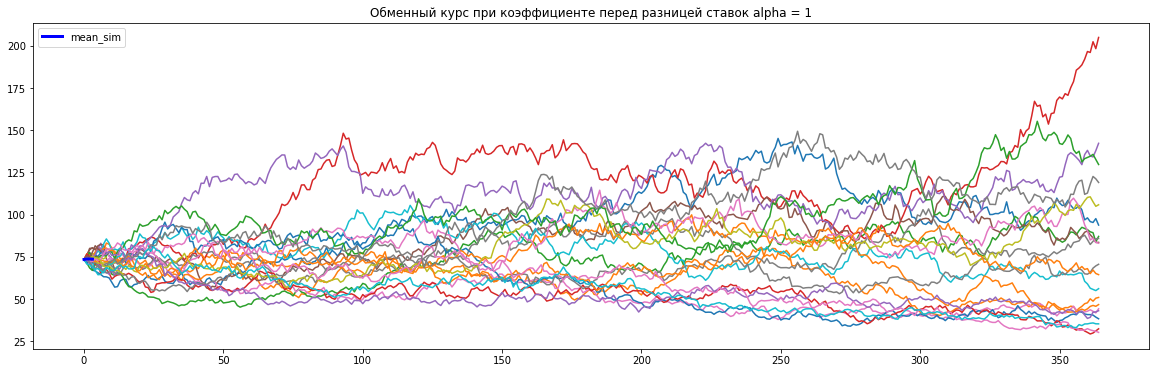

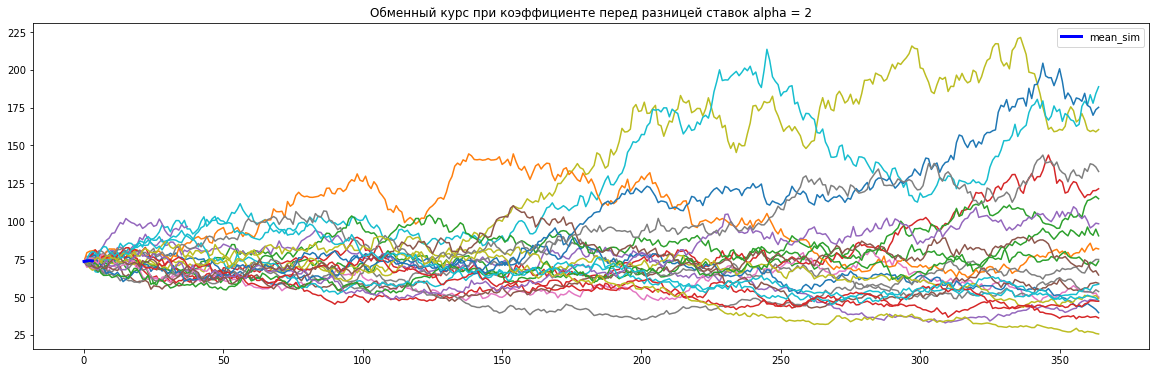

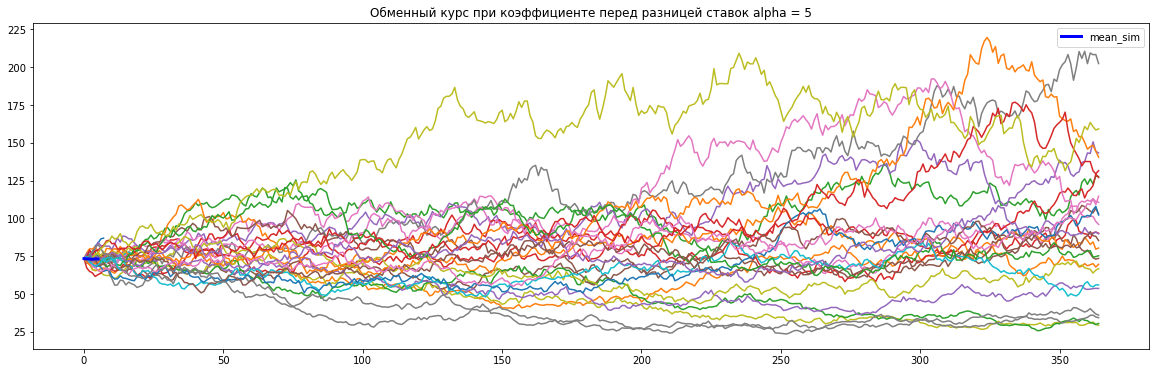

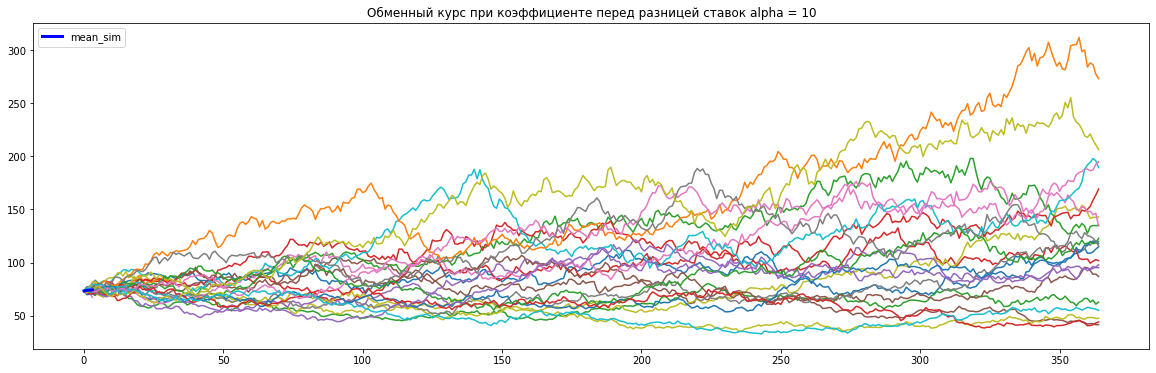

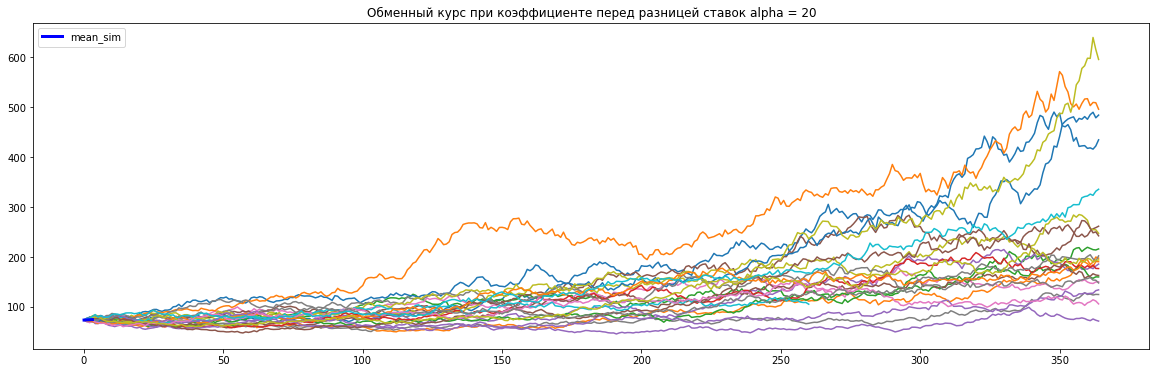

In [35]:
def cir_model_increments(df, num_simulations, T, dt, kappa_usd, theta_usd, sigma_usd, kappa_rub, theta_rub,
              sigma_rub, kappa_exch, theta_exch, sigma_exch, start_date, exch_alpha = 5): 
    
    df = df.dropna()
    num_periods = int(T / dt)
    rub_list = []
    usd_list = []
    ech_list = []
    cholesky_matrix = np.linalg.cholesky(df.corr())
    
    for sim in range(num_simulations):
        rates_dollar = np.zeros(num_periods)
        rates_ruble = np.zeros(num_periods)
        exch_rates = np.zeros(num_periods)

        
        rates_dollar[0] = df[df['date'].dt.date == date.fromisoformat(start_date)].SOFR
        rates_ruble[0] = df[df['date'].dt.date == date.fromisoformat(start_date)].MosPrime
        exch_rates[0] = df[df['date'].dt.date == date.fromisoformat(start_date)].USD_RUB
        
        for i in range(1, num_periods):

            dW = np.random.normal(0, np.sqrt(dt), size = 3)
            dW_corr = cholesky_matrix @ dW
            
            rates_dollar[i] = rates_dollar[i-1]  + kappa_usd * (theta_usd - rates_dollar[i - 1]) + sigma_usd * np.sqrt(rates_dollar[i - 1]) * dW_corr[1]
            rates_ruble[i] = rates_ruble[i-1] + kappa_rub * (theta_rub - rates_ruble[i - 1]) + sigma_rub * np.sqrt(rates_ruble[i - 1]) * dW_corr[0]
            exch_rates[i] = exch_rates[i-1] + exch_alpha * exch_rates[i-1]*(rates_ruble[i-1] - rates_dollar[i-1])* dt + exch_rates[i- 1]* sigma_exch*dW[2]
    
        rub_list.append(rates_ruble)
        usd_list.append(rates_dollar)
        ech_list.append(exch_rates)

    return rub_list, usd_list, ech_list


for exch_alpha in [1, 2, 5, 10, 20]:
    rub_list, usd_list, ech_list = cir_model_increments(df_add, num_simulations=30, T=1.0, dt=1/365,
                    kappa_usd=kappa_usd, theta_usd=theta_usd, sigma_usd=sigma_usd,
                    kappa_rub=kappa_rub, theta_rub=theta_rub, sigma_rub=sigma_rub, 
                    kappa_exch=kappa_exch, theta_exch=theta_exch, sigma_exch=sigma_exch, start_date = '2021-12-10', 
                    exch_alpha = exch_alpha)
    plt.figure(figsize = (20,6))

    for i in ech_list:
        plt.plot(i)
    plt.title(f'Обменный курс при коэффициенте перед разницей ставок alpha = {exch_alpha}')
    plt.plot(np.mean(np.array(ech_list), axis = 0), linewidth = 3, c= 'b', label = 'mean_sim')
    plt.legend()

    plt.show()

В симуляциях выше мы видим, что разница процентных ставок действительно практически не оказывала влияния на обменный курс. Поэтому при увеличении коэффициента альфа перед этим слагаемым, мы видим увеличение разброса симулируемого риск-фактора (особенно при альфа = 20)

### Оптимальное число симуляций
А теперь мы хотим посмотреть, какое нам нужно число симуляций, чтобы посчитанное значение accrual range сходилось к константе

Text(0.5, 1.0, 'Значение справедливой стоимости accrual range от колва проведенных симуляций')

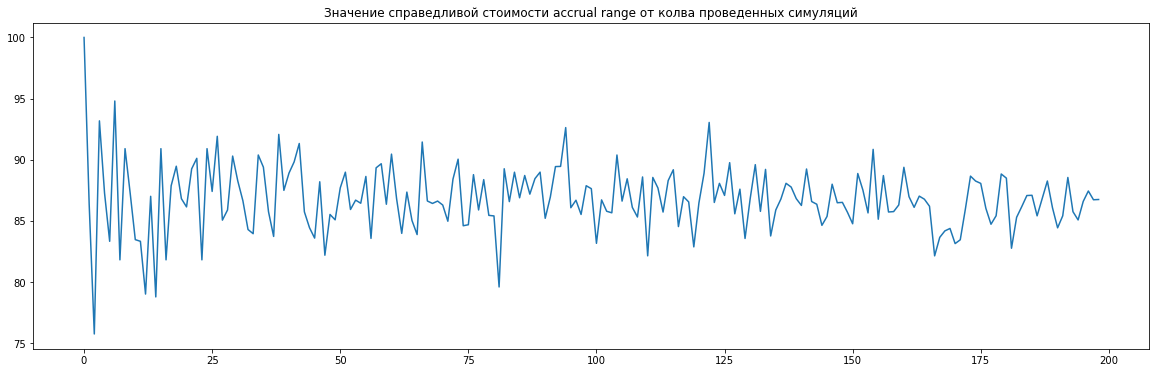

In [36]:
fair_rates = []
for numm in range(1, 200):
    num_days_add, sim_data_add = sumilate_dataset(df, numm , '2021-12-10', '2021-12-27')
    fair_rate = calculate_pricing(df = sim_data_add, upper_bound  = 78, lower_bound = None, nominal = 100)
    fair_rates.append(fair_rate)

plt.figure(figsize = (20,6))
plt.plot(fair_rates)
plt.title('Значение справедливой стоимости accrual range от колва проведенных симуляций')

- На графике наглядно видно, что при увеличении кол-ва симуляциий для рассчета range accural, мы наблюадем постепенную стагнацию тренда к застою/константному значению с небольшой волатильностью (построили только на примере для 200-ста симуляций тк на большее кол-во не хватает мощи kernel-а). 
- Таким образом, оптимальным будет выбор n-кол-ва симуляций >=85. 

При этом оптимальный шаг симуляции определяется двумя факторами: гранулярность данных и используемый период для расчета исторических значений параметров. Тк единственный доступный вариант гранулярности данных - день, а для расчета исторических параметров мы использовали год, наиболее оптимальным шагом мы выбрали симуляцию 365 дней 